# ResNet18-U-Net: Experiments with a Pretrained Encoder

To improve the baseline U-Net, we use a **ResNet18 pretrained on ImageNet** as the encoder.

We compare three experiments: a frozen encoder, training with `ReduceLROnPlateau`, and fine-tuning the last encoder block (`layer4`). We also analyze prediction errors on the validation set.

All models have already been trained. This notebook evaluates the saved checkpoints without additional training. Training histories are available in [Weights & Biases](https://wandb.ai/arzushkaB/image-colorization).

## 1. Architecture and Data Preparation

ResNet18 expects three-channel RGB images, while our input consists of a single normalized **L channel**.

In `ResNetUNet`, the L channel is repeated three times and normalized using ImageNet statistics. The pretrained encoder extracts image features, while the U-Net decoder predicts the two **ab color channels** using skip connections.

All experiments use L1 Loss, 128 × 128 images, a batch size of 32, and the same PASCAL VOC 2012 train/validation/test split.


In [ ]:
from pathlib import Path
import sys
import numpy as np
import torch
import matplotlib.pyplot as plt
from torch import nn
from torch.utils.data import DataLoader
from torchvision import transforms
from skimage.color import lab2rgb

PROJECT_ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                     if (p / "VOCdevkit" / "VOC2012" / "JPEGImages").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Project root not found. Check the VOC2012 directory.")

PACKAGE_ROOT = PROJECT_ROOT / "src" if (PROJECT_ROOT / "src" / "image_colorization").is_dir() else PROJECT_ROOT
if str(PACKAGE_ROOT) not in sys.path:
    sys.path.insert(0, str(PACKAGE_ROOT))

from image_colorization.resnet_unet import ResNetUNet
from image_colorization.dataset import ColorizationDataset
from image_colorization.color_utils import denormalize_lab

IMAGES_DIR = PROJECT_ROOT / "VOCdevkit" / "VOC2012" / "JPEGImages"
VAL_PATH = PROJECT_ROOT / "data" / "splits" / "val.txt"
CHECKPOINTS_DIR = PROJECT_ROOT / "checkpoints"
BATCH_SIZE = 32
IMAGE_SIZE = 128
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")

In [ ]:
val_transform = transforms.Compose([transforms.Resize(IMAGE_SIZE), transforms.CenterCrop(IMAGE_SIZE)])
val_dataset = ColorizationDataset(IMAGES_DIR, VAL_PATH, transform=val_transform)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

checkpoints = {
    "Frozen encoder": CHECKPOINTS_DIR / "resnet18_unet_frozen_encoder_best.pt",
    "Scheduler": CHECKPOINTS_DIR / "resnet18_unet_frozen_scheduler_best.pt",
    "Fine-tuning": CHECKPOINTS_DIR / "resnet18_unet_finetune_layer4_best.pt"
}
print("Validation images:", len(val_dataset))
print("Device:", device)

Validation images: 2569
Device: mps


## 2. Frozen ResNet18 Encoder

In the first experiment, ResNet18 was used as a **frozen encoder**, while only the U-Net decoder was trained. The initial configuration included AdamW, a learning rate of `1e-3`, 20 epochs, and no scheduler.

The best checkpoint was saved at **epoch 9**. On a single validation batch of 32 images, the model achieved an L1 loss of **0.06049**, compared to **0.06416** for the grayscale baseline and **0.06227** for U-Net after 40 epochs.

**Colorization Examples**

The model reconstructs some natural colors and object boundaries, but saturated colors often appear beige or brown.

The following visualization shows the first six images from the original experiment.


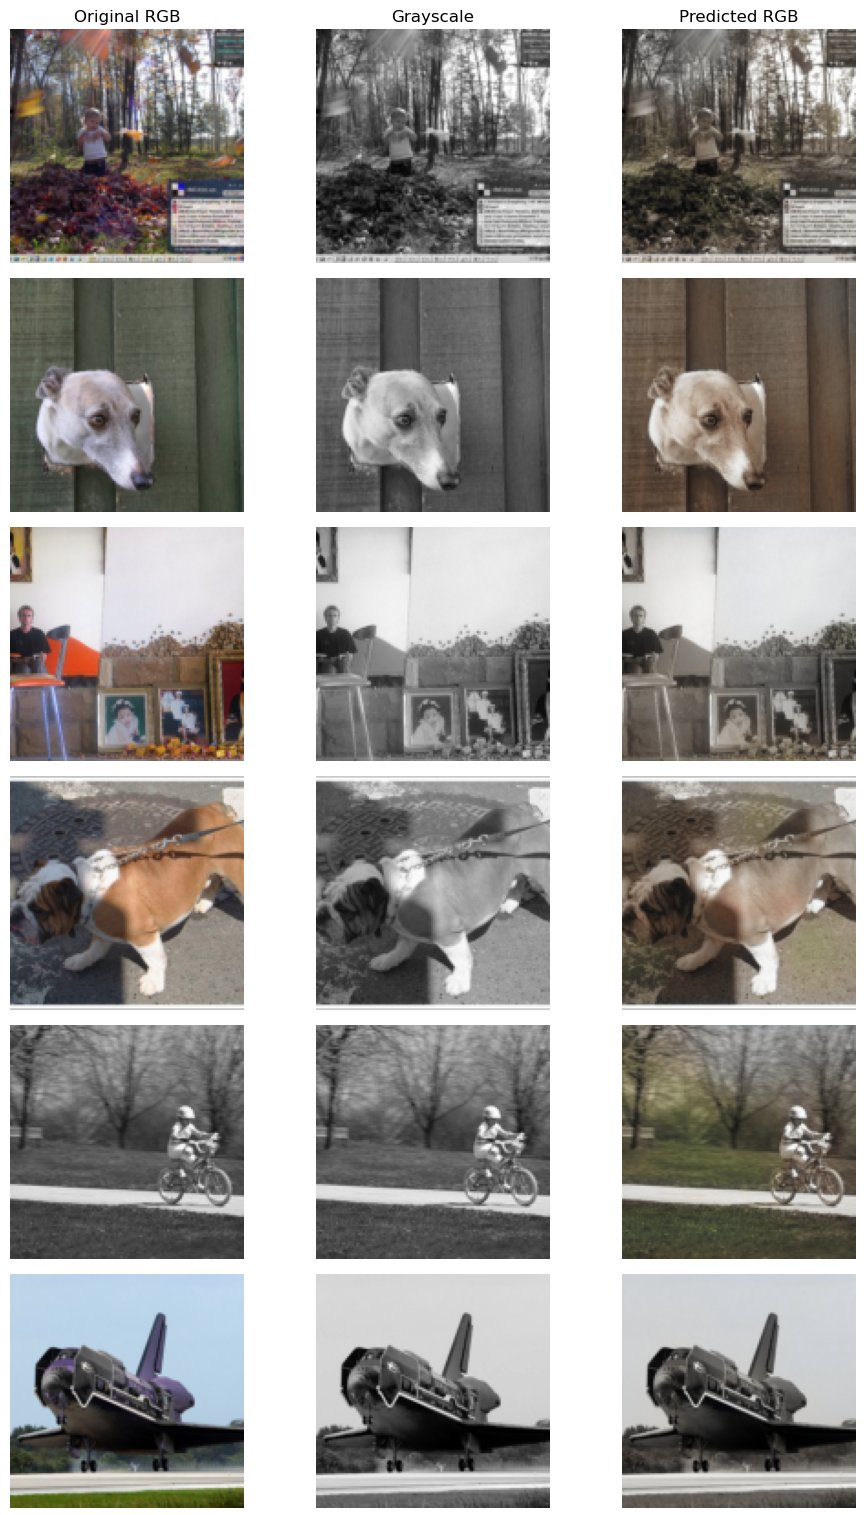

### Color Channel Analysis

On the same validation batch, the mean absolute values of the predicted a and b channels are lower than those of the ground truth. This indicates that even with a pretrained ResNet18 encoder, the model still tends to predict less saturated colors.

| Channel | Ground Truth | Predicted |
|---|---:|---:|
| Mean \|a\| | 0.04468 | 0.01282 |
| Mean \|b\| | 0.08365 | 0.04898 |


## 3. Frozen Encoder + ReduceLROnPlateau

In the second experiment, the ResNet18 encoder remained frozen, but a `ReduceLROnPlateau` scheduler was added to reduce the learning rate when the validation loss stopped improving.

**Training Configuration:** 40 epochs, AdamW (`lr=1e-3`), `factor=0.5`, `patience=3`, `min_lr=1e-5`.

The best checkpoint was saved at **epoch 7**, with a validation L1 loss of **0.06050**. By epoch 40, the validation loss had increased to **0.06315**. On a separate validation batch, the best model achieved **0.06080**, compared to **0.06413** for the grayscale baseline.

Since this experiment used a different random initialization of the decoder, the results cannot be attributed solely to the scheduler.


**Training History with ReduceLROnPlateau**

The training loss continued to decrease, while the validation loss started increasing after reaching an early minimum.

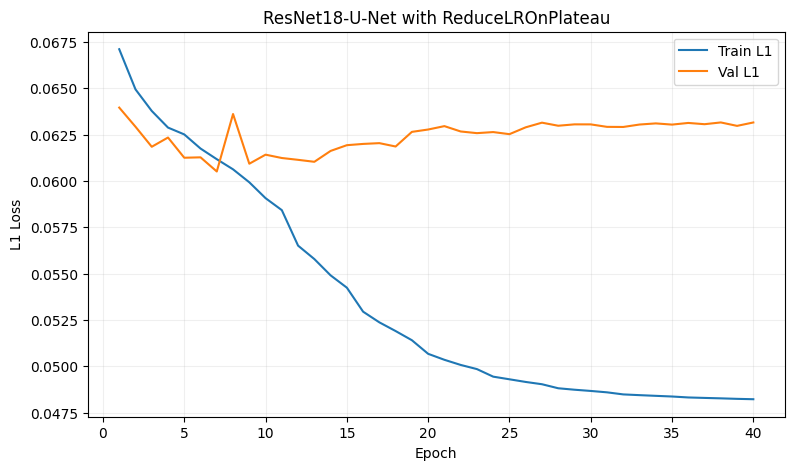

**Colorization Examples with ReduceLROnPlateau**

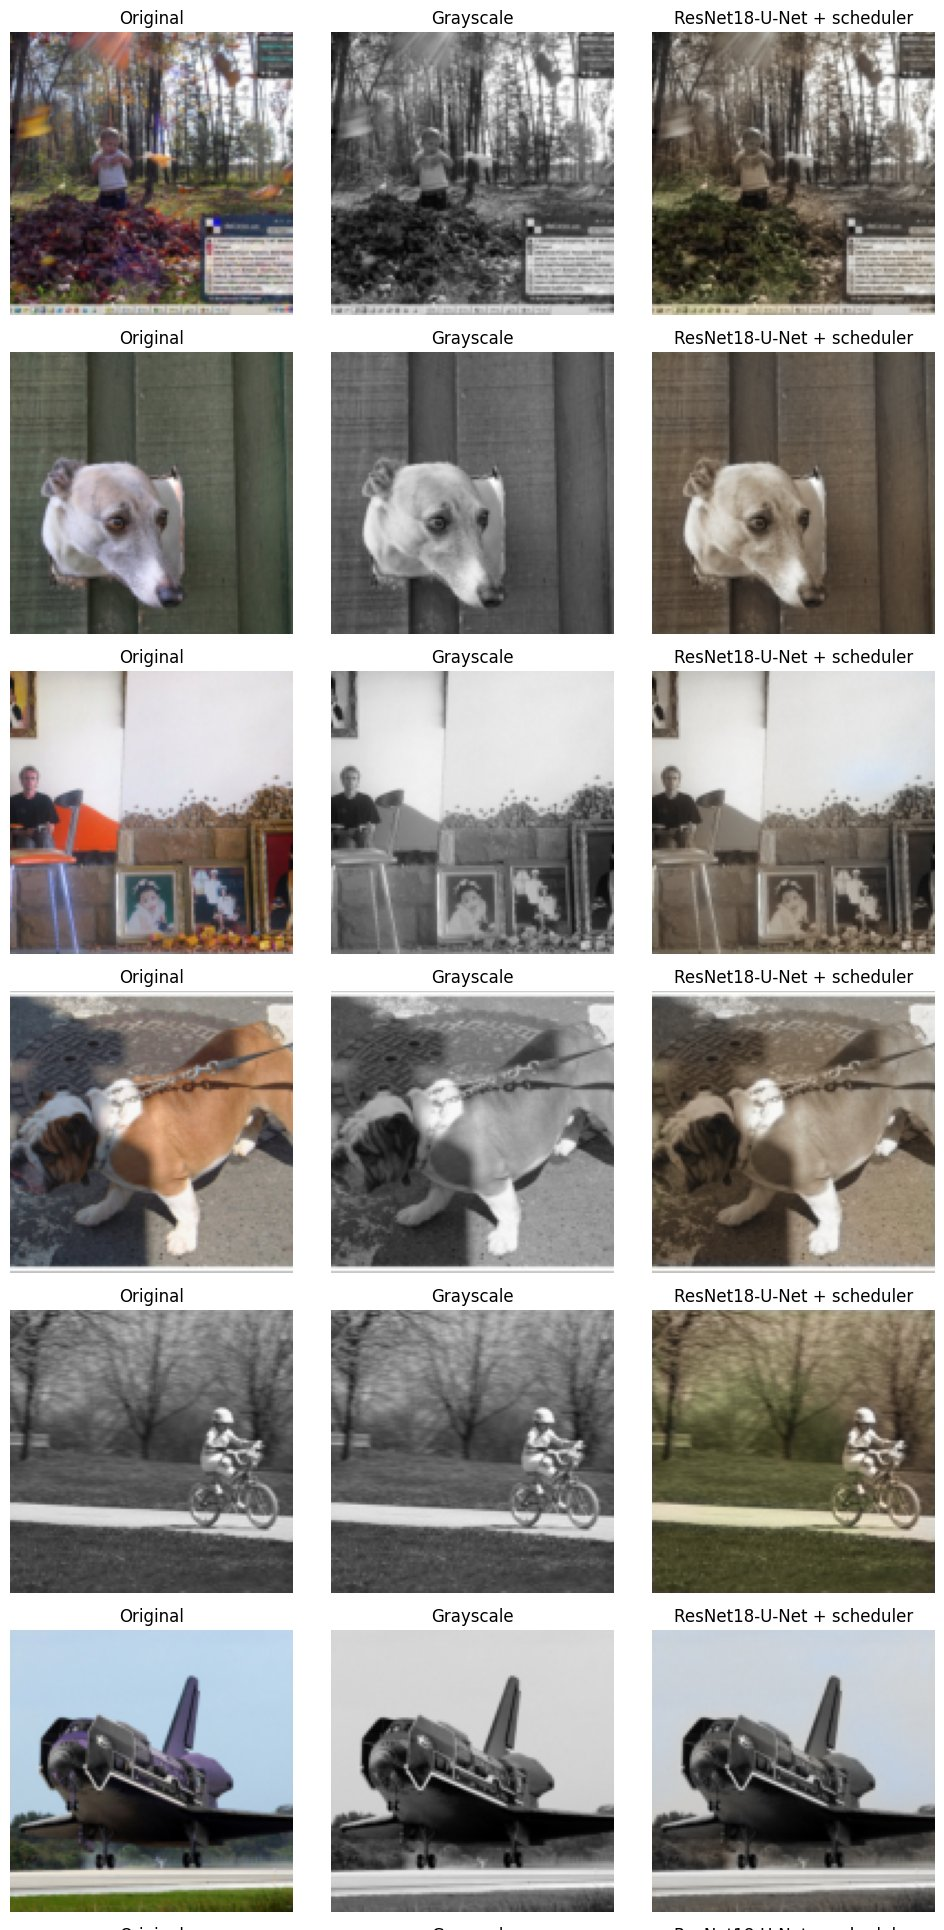

## 4. Fine-tuning layer4

In the third experiment, we loaded the best checkpoint from the initial frozen encoder experiment and unfroze only the last ResNet18 block (`layer4`). The rest of the encoder remained frozen, while the decoder continued training.

**Training Configuration:** 20 epochs, AdamW, `lr=1e-5` for `layer4` and `lr=1e-4` for the decoder. No scheduler was used.

The best validation L1 loss was **0.05962 at epoch 1**. By epoch 20, the validation loss had increased to **0.06254**, despite the training loss decreasing to **0.04291**. On the original validation batch, the best model achieved an L1 loss of **0.06168**.

**Fine-tuning Training History**

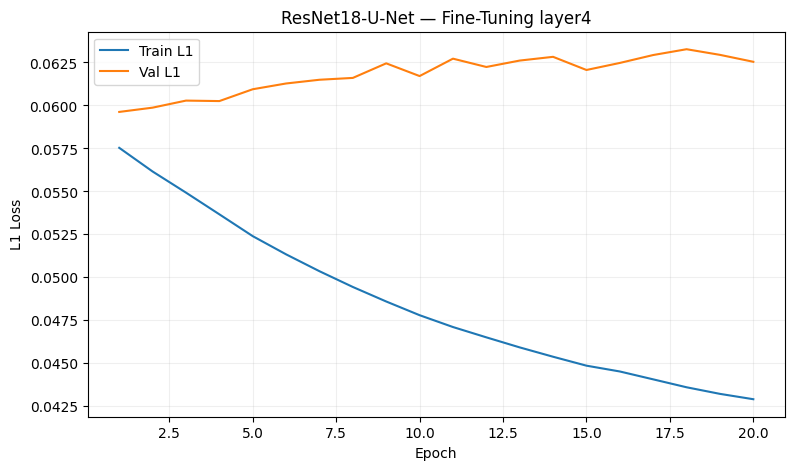

## 5. Model Comparison

The table below summarizes the results from the original experiments. Since the metrics were calculated on different validation batches, they cannot be used for a direct comparison under identical conditions.

| Model | Best Checkpoint | Batch L1 | Grayscale Baseline L1 |
|---|---|---:|---:|
| Frozen ResNet18 | Epoch 9 | 0.06049 | 0.06416 |
| ResNet18 + Scheduler | Epoch 7 | 0.06080 | 0.06413 |
| Fine-tuning `layer4` | Epoch 1 | 0.06168 | 0.06413 |

For a more reliable comparison, we load all three checkpoints and evaluate them on the same validation batch.


In [ ]:
L, ab = next(iter(val_loader))
criterion = nn.L1Loss()
print("Grayscale L1:", criterion(torch.zeros_like(ab), ab).item())

model = ResNetUNet().to(device)
predictions = {}
for name, path in checkpoints.items():
    checkpoint = torch.load(path, map_location=device, weights_only=True)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()
    with torch.inference_mode():
        predictions[name] = model(L.to(device)).cpu()
    print(f"{name} (epoch {checkpoint['epoch']}):", criterion(predictions[name], ab).item())

Grayscale L1: 0.06416293978691101
Frozen encoder (epoch 9): 0.06049323454499245
Scheduler (epoch 7): 0.060842469334602356
Fine-tuning (epoch 1): 0.06172499060630798


In [ ]:
n_show = min(5, len(L))
fig, axes = plt.subplots(n_show, 5, figsize=(15, n_show * 2.5), squeeze=False)

for i in range(n_show):
    lightness = L[i, 0].numpy()
    true_ab = ab[i].permute(1, 2, 0).numpy()
    images = [lab2rgb(denormalize_lab(lightness, true_ab)), lightness]
    for name in checkpoints:
        pred_ab = predictions[name][i].permute(1, 2, 0).numpy()
        images.append(lab2rgb(denormalize_lab(lightness, pred_ab)))
    for ax, img in zip(axes[i], images):
        ax.imshow(img, cmap="gray" if img.ndim == 2 else None, vmin=0 if img.ndim == 2 else None, vmax=1 if img.ndim == 2 else None)
        ax.axis("off")

for ax, title in zip(axes[0], ["Original RGB", "L channel", *checkpoints.keys()]):
    ax.set_title(title)
plt.tight_layout()
plt.show()

## 6. Error Analysis: Frozen ResNet18-U-Net

For the initial frozen encoder experiment, we calculated the L1 loss for each image in the entire validation set (2,569 images). This provides a more representative evaluation than using a single batch.

| Metric | Value |
|---|---:|
| Mean model L1 | 0.0597 |
| Median model L1 | 0.0531 |
| 90th percentile L1 | 0.1007 |
| Mean grayscale L1 | 0.0689 |
| Images where the model outperforms the grayscale baseline | 71.4% |

We define `ΔL1 = L1_gray - L1_model`. A positive value indicates that the model produces a lower error than the grayscale baseline (`ab = 0`).

**Error Distribution and Grayscale Baseline Comparison**

In the scatter plot, points below the dashed diagonal represent images where ResNet18-U-Net achieves a lower L1 loss than the grayscale baseline.


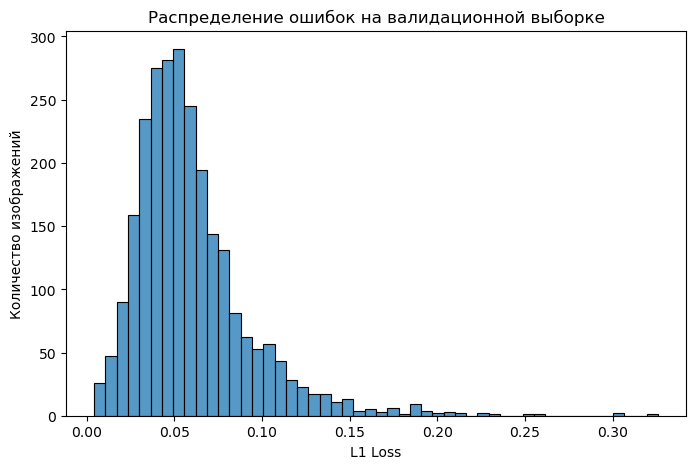

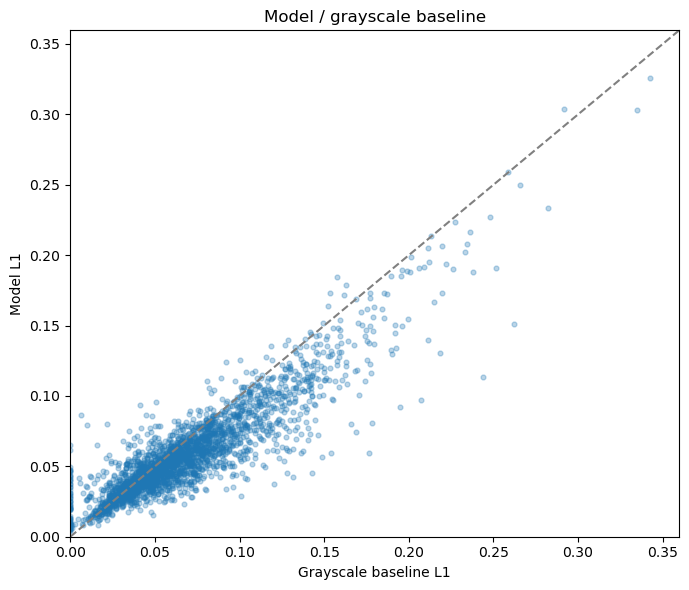

### Examples with Different Error Levels

We divide the images into three groups based on their L1 loss: low (< 0.02), typical (0.04–0.06), and high (> 0.18).

Images with low L1 loss often have naturally desaturated colors, while images with high L1 loss tend to contain bright colors that the model replaces with more neutral tones.

**Low L1 — Examples with Small Errors**

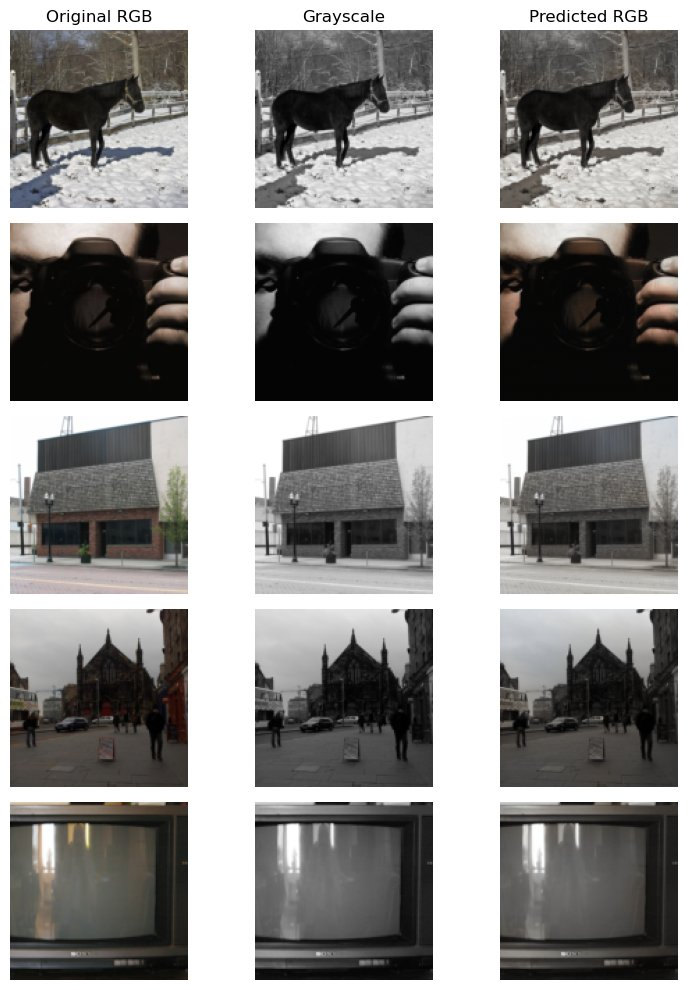

**Typical L1 — Representative Examples**

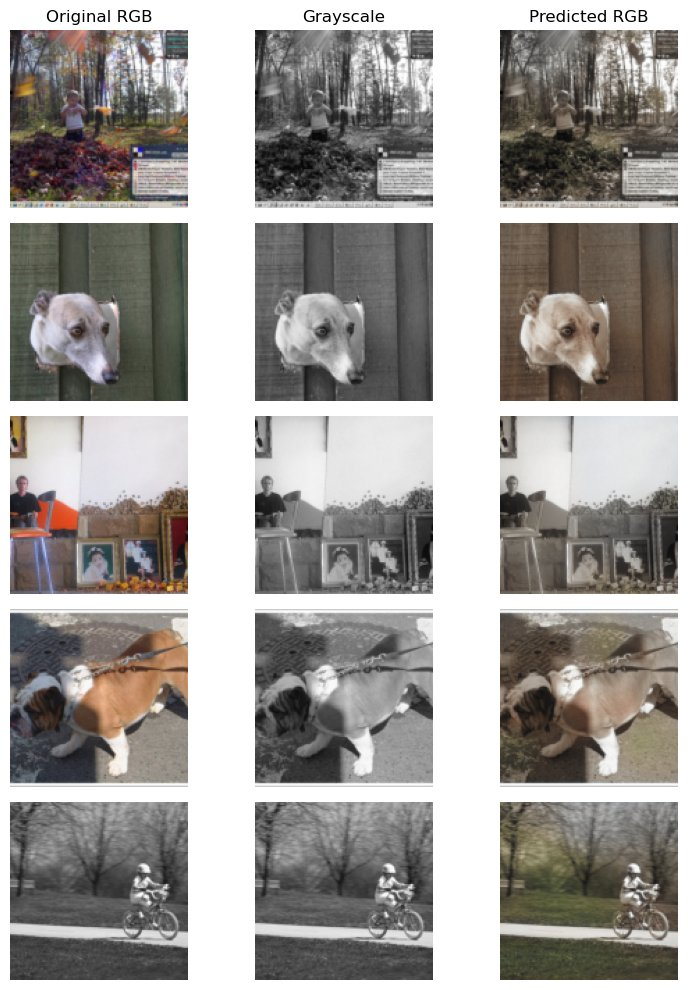

**High L1 — Examples with Large Errors**

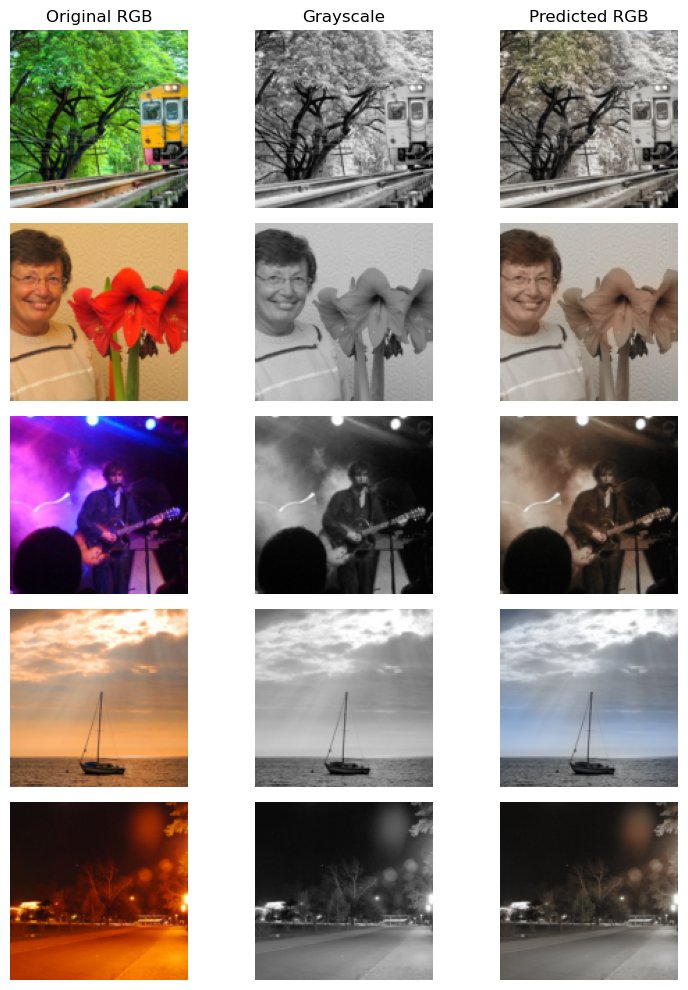


### Full Validation Set Re-evaluation

We evaluate the frozen encoder model on the entire validation set to recalculate the L1 metrics. Only inference is performed; no additional training is required.


In [ ]:
model.load_state_dict(torch.load(checkpoints["Frozen encoder"], map_location=device, weights_only=True)["model_state_dict"])
model.eval()
losses, gray_losses = [], []

with torch.inference_mode():
    for L_batch, ab_batch in val_loader:
        pred = model(L_batch.to(device)).cpu()
        losses.extend((pred - ab_batch).abs().mean(dim=(1, 2, 3)).tolist())
        gray_losses.extend(ab_batch.abs().mean(dim=(1, 2, 3)).tolist())

delta = np.array(gray_losses) - np.array(losses)
print("Validation images:", len(losses))
print("Mean model L1:", round(np.mean(losses), 4))
print("Mean grayscale L1:", round(np.mean(gray_losses), 4))
print("Model better:", f"{(delta > 0).mean():.1%}")

## 7. Conclusions

The pretrained ResNet18 encoder improved the L1 loss compared to the original U-Net and provided better color reconstruction for some images. However, the predicted colors remained mostly desaturated.

In the `ReduceLROnPlateau` experiment, longer training did not improve the validation loss. During `layer4` fine-tuning, the lowest validation loss was achieved at the first epoch. After that, the training loss continued to decrease while the validation loss increased, indicating overfitting.

Evaluation on the entire validation set showed that the frozen encoder model outperformed the grayscale baseline on **71.4% of images**. However, a low L1 loss does not necessarily indicate visually accurate or saturated colorization.

In the following experiments, we will explore predicting distributions over color classes instead of directly regressing the ab channels.
